![Banner](../../../../Images/Banner/07_remote_sensing/09_03_banner_rs_rader.png)


# RADARSAT Constellation Mission (RCM) InSAR Processing

A real two-pass interferometric workflow on RCM Level-1 Stripmap SLC data, following the
*InSAR processing (SLC)* section of `07_03_02_00_RADARSAT_intro.ipynb`: pair selection,
DEM-assisted coregistration, interferogram and coherence, topographic phase removal, Goldstein
filtering, phase unwrapping, phase-to-displacement conversion, and geocoding.


## Overview

A real two-pass interferometric workflow on RCM Level-1 Stripmap SLC data, following the
*InSAR processing (SLC)* section of `07_03_02_00_RADARSAT_intro.ipynb`: pair selection,
DEM-assisted coregistration, interferogram and coherence, topographic phase removal, Goldstein
filtering, phase unwrapping, phase-to-displacement conversion, and geocoding.


## Core concepts

### Learning objectives

1. Select an RCM Stripmap SLC pair with the same beam, pass, and relative orbit and a short temporal baseline.
2. Read the RCM product annotation into the metadata shape the Sentinel-1 coregistration functions expect.
3. Coregister the secondary SLC to the reference with DEM-assisted back-geocoding and spline resampling.
4. Form a differential interferogram, subtract the DEM topographic phase, and estimate coherence.
5. Filter the wrapped phase with a Goldstein filter and unwrap it with SNAPHU above a coherence threshold.
6. Convert unwrapped phase to line-of-sight displacement using the C-band wavelength.
7. Geocode coherence and displacement for the Montreal pair and interpret coherent patches that unwrap as isolated islands.

### Contents

1. Real-data example: Montreal, 4-day repeat
2. Takeaways and limitations


## Real-data example: Montreal, 4-day repeat

**Pair selection (Step 1 of the InSAR workflow).** The intro notebook's advice is to use the
same beam mode, orbit direction and satellite geometry, prefer a short temporal baseline (RCM's
4-day repeat is the headline advantage here), and prefer a small perpendicular baseline. None of
the RADARSAT data already in `data/` satisfies this -- every cached RADARSAT-2 scene is a
different beam mode (so a different geometry entirely), and the one cached RCM product is a
single date. Searching NRCan/EODMS's `RCMImageProducts` STAC collection directly (not just the
`rcm-ard` collection the GRD tutorial used) over Montreal turned up a clean candidate:

| | Reference | Secondary |
|---|---|---|
| Product | `RCM1_..._16M11_20230913_224404_VV_SLC` | `RCM2_..._16M11_20230917_224416_VV_SLC` |
| Date | 2023-09-13 | 2023-09-17 (4 days later) |
| Beam | 16M11 (16 m Stripmap, single-look) | 16M11 |
| Relative orbit | 15 (ascending) | 15 (ascending) |
| Polarisation | VV | VV |

Both were downloaded from EODMS's Data Delivery Service (`/dds/v1/item/...`, bearer-token
auth from an Earthdata-Login-style password grant) and are cached under
`Data/08_remote_sensing/08_03_radar/rcm_insar_montreal/`.

**What's new here.** RCM Level-1 Stripmap SLC has no TOPS bursts to deburst and no separate
orbit file to fetch (its `product.xml` carries its own precise state vectors) -- so the only
missing piece was a reader for that geometry: `geolattice.rsense.sar.radarsat.read_rcm_annotation`
parses it into the same shape `geolattice.rsense.sar.sentinel1.read_slc_annotation` returns for one
Sentinel-1 burst (one entry in `bursts` covering the whole image), which means
`sentinel1.back_geocode` and `sentinel1.resample_slc` (called with `ann=None`, since Stripmap
has no TOPS steering to deramp) work on it completely unchanged, and the rest of the chain
(`geolattice.rsense.insar`) was already sensor-agnostic.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Load the two RCM Stripmap SLC products (reference 2023-09-13, secondary 2023-09-17,
# a 4-day repeat over Montreal) and read their annotation metadata (Step 1: pair selection).

# 1. Silence third-party warnings (e.g. from rasterio/rioxarray) so the printed output below
#    stays readable; this notebook isn't demonstrating those libraries' warning behaviour.
import warnings
warnings.filterwarnings("ignore")  # hide library warnings


# 2. Standard library / third-party imports used throughout the notebook: time.time() for
#    timing the slower InSAR steps, Path for the cached-data layout, matplotlib/numpy for
#    plotting and array math, and rasterio/rioxarray for reading the SLC and DEM rasters.
import time
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rasterio  # raster reading
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar  # InSAR tools
from geolattice.rsense.sar import radarsat, sentinel1 as s1  # RCM readers and Sentinel-1 tools (reused for RCM)


# 3. geolattice.rsense.insar holds the sensor-agnostic InSAR processing chain (interferogram,
#    coherence, filtering, unwrapping, phase-to-displacement); geolattice.rsense.sar.radarsat
#    is the new RCM-specific annotation reader; sentinel1 (aliased s1) supplies
#    back_geocode/resample_slc/terrain_correct, which work unchanged on RCM Stripmap once
#    radarsat.read_rcm_annotation shapes its metadata like a Sentinel-1 burst.

# 4. Bump the default figure DPI so the InSAR phase/coherence plots below are crisp.
plt.rcParams.update({"figure.dpi": 110})


# 5. Paths to the two cached RCM products (downloaded from EODMS) and their VV SLC GeoTIFFs --
#    REF is the earlier (2023-09-13) acquisition, SEC the later (2023-09-17) one, 4 days apart.
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/rcm_insar_montreal")
# reference RCM SLC product (13 September 2023)
REF_DIR = CACHE / "RCM1_OK2678697_PK2744956_1_16M11_20230913_224404_VV_SLC"
# secondary RCM SLC product (17 September 2023)
SEC_DIR = CACHE / "RCM2_OK2678697_PK2750939_1_16M11_20230917_224416_VV_SLC"
# the complex VV images
REF_TIF, SEC_TIF = REF_DIR / "imagery/2744956_1_VV.tif", SEC_DIR / "imagery/2750939_1_VV.tif"


# 6. Parse each product.xml into the same annotation dict shape Sentinel-1 reading returns
#    (one "burst" covering the whole Stripmap scene), so the rest of the sensor-agnostic
#    InSAR chain below can treat this RCM pair exactly like a Sentinel-1 pair.
ann_ref = radarsat.read_rcm_annotation(REF_DIR / "metadata/product.xml")
ann_sec = radarsat.read_rcm_annotation(SEC_DIR / "metadata/product.xml")  # annotation of the secondary


# 7. Print per-scene metadata (mission, beam, orbit pass, polarisation, dimensions, incidence
#    angle range, pixel spacing) so we can confirm -- per Step 1 -- that both products really
#    do share the same beam mode and geometry, then report the temporal baseline (4 days,
#    RCM's headline advantage) and the radar wavelength used later for phase-to-displacement.
baseline_days = 4
print(f"geolattice.rsense {rs.__version__}")  # GeoLattice version
for name, ann in (("reference", ann_ref), ("secondary", ann_sec)):  # both products
    # mission, beam, pass and polarisation
    print(f"{name}: {ann['mission']} {ann['beam']} {ann['pass']} {ann['polarisation']}, "
          f"{ann['lines_per_burst']} x {ann['samples_per_burst']}, incidence "
          f"{ann['incidence_near']:.2f}-{ann['incidence_far']:.2f} deg, "
          f"pixel spacing {ann['azimuth_pixel_spacing']:.2f} m (az) x {ann['range_pixel_spacing']:.2f} m (rg)")
# temporal baseline and wavelength
print(f"temporal baseline: {baseline_days} days | wavelength {ann_ref['wavelength'] * 100:.2f} cm")

geolattice.rsense 0.2.0.dev0
reference: RCM-1 16M11 Ascending VV, 7163 x 2697, incidence 36.90-39.04 deg, pixel spacing 2.53 m (az) x 6.97 m (rg)
secondary: RCM-2 16M11 Ascending VV, 7155 x 2697, incidence 36.90-39.04 deg, pixel spacing 2.53 m (az) x 6.97 m (rg)
temporal baseline: 4 days | wavelength 5.55 cm


Both products report essentially the same incidence-angle range and pixel spacing, confirming
they really do share the same beam and orbit tube -- exactly what Step 1 asks for.


### Coregistration

`back_geocode` locates every Copernicus GLO-30 DEM cell (ellipsoidal heights) in both products'
geometry with `geo2rdr` on their own precise orbits, giving each reference pixel the secondary
position to resample (`sec_line`/`sec_sample`), the DEM-surface range difference
(`delta_range`, what the topographic phase in Step 4 needs) and the local incidence angle.
`resample_slc(..., ann=None)` then does plain spline interpolation -- no TOPS deramp/reramp,
since Stripmap has none.


In [2]:
# Step 2: coregister the secondary SLC onto the reference SLC's geometry via DEM-assisted
# geo2rdr/resampling, so every pixel pair below compares the same ground location.

# 1. RCM SLC GeoTIFFs store the complex sample as two real bands (I and Q); combine them
#    into one complex64 array, which is the natural representation for SAR phase math.
def read_slc(path):
    with rasterio.open(path) as src:  # open the SLC GeoTIFF
        # band 1 = real part, band 2 = imaginary part
        return (src.read(1) + 1j * src.read(2)).astype("complex64")



# 2. Load both SLC rasters into memory as complex arrays (still in their own radar geometry,
#    not yet coregistered).
slc_ref, slc_sec = read_slc(REF_TIF), read_slc(SEC_TIF)


# 3. Build (once) a Copernicus GLO-30 DEM over the scene, cached to disk so this expensive
#    download/merge only happens the first time the notebook is run.
dem_path = CACHE / "copdem30_ellipsoid.tif"
if not dem_path.exists():  # download the DEM once
    import planetary_computer as pc  # Planetary Computer URL signing
    import pystac_client  # STAC search client
    from rioxarray.merge import merge_arrays  # mosaic several rasters

    box = (-73.70, 45.40, -73.20, 45.68)  # Montreal box
    # open the Planetary Computer STAC catalogue
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
    # Copernicus DEM tiles clipped to the box
    tiles = [rioxarray.open_rasterio(i.assets["data"].href).squeeze("band", drop=True).rio.clip_box(*box)
             for i in cat.search(collections=["cop-dem-glo-30"], bbox=box).items()]
    dem_geoid = merge_arrays(tiles).astype("float32")  # mosaic them
    # convert to ellipsoid heights and save
    insar.geoid_to_ellipsoid(dem_geoid, "EGM2008").rio.to_raster(dem_path)

#    STAC serves Copernicus DEM heights above the EGM2008 geoid; geo2rdr (inside
#    back_geocode below) needs ellipsoidal heights, so convert and write the result out
#    before loading it back for use.
dem = rioxarray.open_rasterio(dem_path).squeeze(drop=True)


# 4. back_geocode: for every reference-image pixel, locate the matching position in the
#    secondary image via geo2rdr on each product's own precise orbit and this DEM --
#    returning the secondary (line, sample) to resample, the DEM-surface range difference
#    (delta_range, the topographic-phase ingredient Step 3 needs below) and the local
#    incidence angle. Timed since this is one of the slower steps.
t0 = time.time()
# back-geocoding: where each reference pixel falls in the secondary image
geom = s1.back_geocode(ann_ref, ann_sec, 0, 0, dem, cols=(0, ann_ref["samples_per_burst"]))
# run time and range of the range offsets
print(f"back_geocode: {time.time() - t0:.0f} s | delta_range {geom['delta_range'].min():.2f}-"
      f"{geom['delta_range'].max():.2f} m | incidence {geom['incidence'].min():.2f}-{geom['incidence'].max():.2f} deg")

t0 = time.time()  # start the timer

# 5. resample_slc: interpolate the secondary SLC onto the reference grid at the positions
#    geo2rdr located above (cubic spline, order=3). ann=None skips the TOPS deramp/reramp
#    Sentinel-1's burst mode needs, since RCM Stripmap has no equivalent steering to undo.
#    The result is directly comparable, pixel-for-pixel, against slc_ref.
resampled = s1.resample_slc(slc_sec, geom["sec_line"], geom["sec_sample"], ann=None, order=3)
# run time and valid overlap
print(f"resample_slc: {time.time() - t0:.1f} s, {100 * np.mean(resampled != 0):.1f}% valid overlap")

back_geocode: 64 s | delta_range 24.99-26.37 m | incidence 36.87-39.01 deg


resample_slc: 5.4 s, 96.0% valid overlap


A delta_range of 25-26 m across the whole scene is a small, smoothly-varying perpendicular
baseline -- exactly what Step 1 wants for a deformation-sensitive pair, and consistent with
this being a genuine same-track repeat rather than an incidentally-overlapping different track
(the kind of mismatch the compact-pol and GRD tutorials' own RADARSAT-2 archive scenes turned
out to have, and why this pair was fetched fresh from EODMS instead).


### Interferogram and coherence

`differential_interferogram` multiplies the reference by the resampled secondary's conjugate
and removes the DEM-predicted (topographic + flat-Earth) phase in one call, using
`delta_range` directly -- what remains is deformation, atmosphere and noise (this already *is*
differential InSAR, Step 4 of the intro's list, since `back_geocode` supplies the topographic
range difference up front). A 4x4 multilook (about 10 m x 25 m ground cells) estimates
coherence from `geolattice.rsense.insar.multilook_complex`.


coherence: mean 0.35, median 0.35, 59% of pixels above 0.3


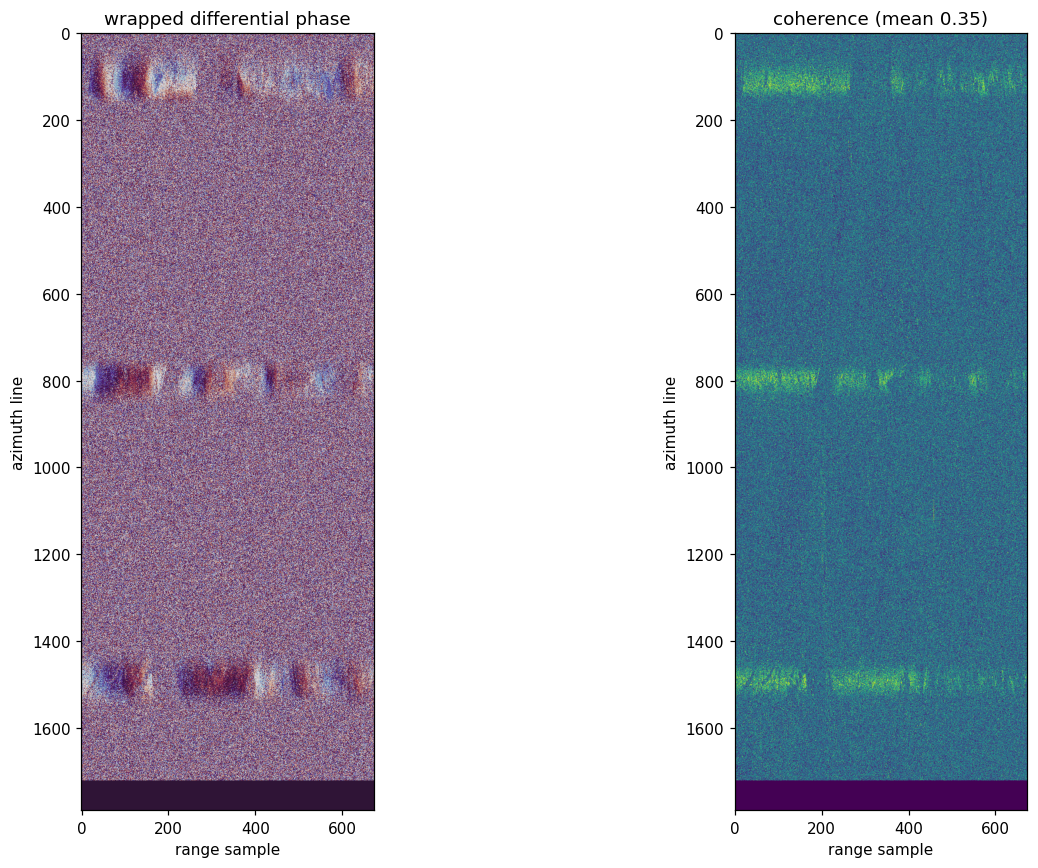

In [3]:
# Step 3: form the differential interferogram, then multilook it to estimate coherence.

# 1. Multilook factor: 4 looks in azimuth x 4 in range, giving ~10 m x 25 m ground cells --
#    used below for the interferogram, the intensities and the coherence estimate alike,
#    so all three are computed over matching resolution cells.
LOOKS = (4, 4)

# 2. differential_interferogram: conjugate-multiply the reference SLC by the coregistered
#    secondary and subtract the DEM-predicted topographic + flat-Earth phase in one call,
#    using delta_range from back_geocode above -- this already *is* a differential
#    interferogram (Step 4 of the intro's list); what remains is deformation, atmosphere
#    and noise.
diff = insar.differential_interferogram(slc_ref, resampled, geom["delta_range"], ann_ref["wavelength"])

# 3. Multilook the (still complex) differential interferogram to reduce speckle before
#    computing/displaying the wrapped phase.
diff_ml = insar.multilook_complex(diff, LOOKS)

# 4. Multilooked intensity of each SLC (|amplitude|^2) -- the normalising terms the sample
#    coherence estimator below needs.
p1 = insar.multilook_complex(np.abs(slc_ref) ** 2, LOOKS)
p2 = insar.multilook_complex(np.abs(resampled) ** 2, LOOKS)  # multilooked secondary intensity

# 5. Sample coherence: magnitude of the multilooked cross-correlation between reference and
#    secondary, normalised by the geometric mean of their multilooked intensities (the tiny
#    epsilon just avoids a divide-by-zero in low-signal areas). Ranges 0 (decorrelated) to
#    1 (perfectly coherent).
coh = np.abs(insar.multilook_complex(slc_ref * np.conj(resampled), LOOKS)) / np.sqrt(p1 * p2 + 1e-30)


# 6. Summarise coherence over the scene, including the fraction above the 0.3 threshold that
#    will matter later for masking unreliable phase.
print(f"coherence: mean {np.nanmean(coh):.2f}, median {np.nanmedian(coh):.2f}, "
      f"{100 * np.mean(coh > 0.3):.0f}% of pixels above 0.3")


# 7. Plot the wrapped differential phase (-pi..pi, cyclic colormap) alongside the coherence
#    map so phase quality and coherence can be compared side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(np.angle(diff_ml), cmap="twilight", vmin=-np.pi, vmax=np.pi)  # wrapped differential phase
axes[0].set_title("wrapped differential phase")  # title
axes[1].imshow(coh, cmap="viridis", vmin=0, vmax=1)  # coherence
axes[1].set_title(f"coherence (mean {np.nanmean(coh):.2f})")  # title
for ax in axes:  # for both panels
    ax.set_xlabel("range sample"); ax.set_ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

Mean coherence of 0.35 over 4 days is plausible for mixed farmland and water at C-band (the
bright, scratchy texture visible in the amplitude image below is agricultural field structure,
not noise) -- this is not an urban scene, so it is not the high-coherence case the coherence
tutorial's Mexico City pairs showed.

A few horizontal bands of visibly higher coherence cut across the whole swath width. They are
real (checked against the DEM-surface range difference and the raw secondary-minus-reference
azimuth offset, both of which vary smoothly with no trace of these bands, and against a plain
interpolation self-test, which ruled out `resample_slc`), and they survive a 4x finer
`back_geocode` sampling step too, so they are not a scatter-interpolation artifact either. Once
geocoded (Step 8 below) they run close to constant latitude, not parallel to the satellite
track the way a radar-geometry processing artifact would -- consistent with Quebec's historic
seigneurial strip-field land division (long, narrow, consistently-oriented agricultural
parcels), where a few specific strips evidently kept a more stable, coherent surface (recently
harvested bare soil, say) than their neighbours over these 4 days. That is a plausible
explanation, not a confirmed one -- it would need an optical image from the same window to
check directly.


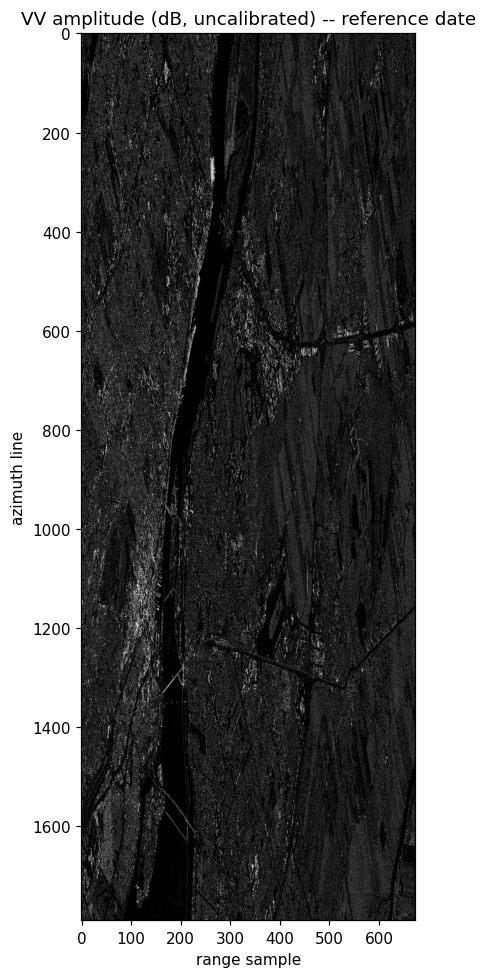

In [4]:
# Show the scene content behind the phase/coherence numbers above, via plain radar amplitude.

# 1. Convert the reference-date multilooked intensity (p1, computed in the coherence cell
#    above) to an uncalibrated dB amplitude image; np.maximum avoids log10(0) in nodata areas.
amp_db = 10 * np.log10(np.maximum(p1, 1e-8))

# 2. Display in grayscale -- the bright, scratchy texture here is agricultural field
#    structure (not noise), useful context for interpreting the coherence banding discussed
#    in the surrounding markdown.
plt.figure(figsize=(6, 9))
plt.imshow(amp_db, cmap="gray", vmin=-10, vmax=20)  # amplitude in dB
plt.title("VV amplitude (dB, uncalibrated) -- reference date")  # title
plt.xlabel("range sample"); plt.ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

### Goldstein filtering

Goldstein adaptive filtering smooths the wrapped phase in the frequency domain before
unwrapping, trading a little resolution for much better phase continuity in noisier areas.


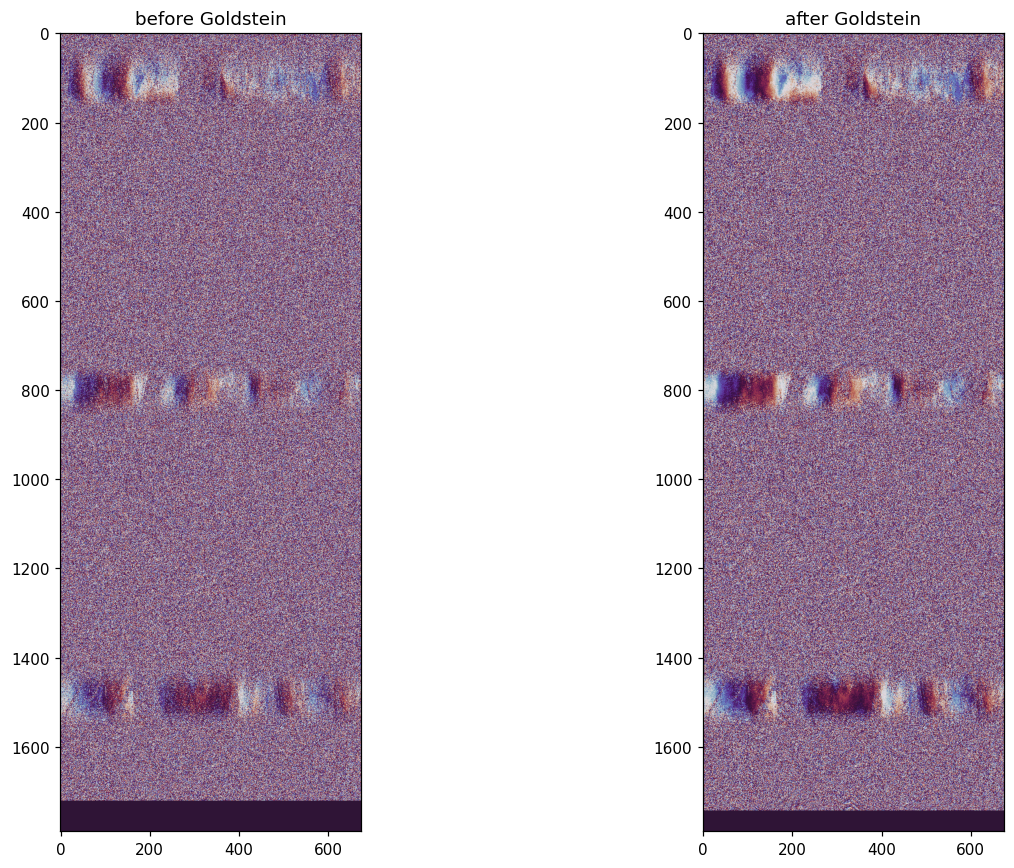

In [5]:
# Steps 4-5: Goldstein-filter the wrapped phase to improve continuity before unwrapping.

# 1. Keep only pixels with finite, nonzero coherence -- Goldstein filtering (and the
#    unwrapping after it) is meaningless where the interferogram itself is undefined.
valid = np.isfinite(diff_ml) & (coh > 0)

# 2. Normalise the (multilooked, complex) interferogram to a unit-magnitude phasor: Goldstein
#    filtering only operates on phase, not amplitude, so strip the amplitude out first.
unit_phasor = np.where(valid, diff_ml / (np.abs(diff_ml) + 1e-30), 0)

# 3. Goldstein adaptive filter: smooths the wrapped phase patch-by-patch in the frequency
#    domain. alpha controls filter strength (higher = more smoothing), patch/overlap set
#    the tile size and overlap used for the per-patch FFT filtering -- trading a little
#    spatial resolution for much better phase continuity in noisier areas.
filtered = insar.goldstein_filter(unit_phasor, alpha=0.6, patch=32, overlap=8)


# 4. Compare the wrapped phase before vs. after filtering to see the continuity improvement.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(np.angle(unit_phasor), cmap="twilight", vmin=-np.pi, vmax=np.pi)  # phase before filtering
axes[0].set_title("before Goldstein")  # title
axes[1].imshow(np.angle(filtered), cmap="twilight", vmin=-np.pi, vmax=np.pi)  # phase after filtering
axes[1].set_title("after Goldstein")  # title
plt.tight_layout()  # arrange

### Phase unwrapping

SNAPHU unwraps the filtered phase, masked to pixels with coherence above 0.3 -- the same
unwrapping-reliability threshold the coherence tutorial used.


In [6]:
# Step 6: unwrap the filtered phase, i.e. resolve its 2*pi ambiguities into a continuous field.

# 1. Time the unwrapping step (SNAPHU is typically the slowest stage of the whole chain).
t0 = time.time()

# 2. Run SNAPHU on the Goldstein-filtered phase, using the "defo" (deformation) statistical
#    cost model, the total look count (az x rg) for its noise-variance weighting, and a
#    coherence > 0.3 mask -- the same unwrapping-reliability threshold the coherence
#    tutorial used -- to exclude pixels too decorrelated to unwrap with confidence.
unwrapped = insar.unwrap(filtered, coh, method="snaphu", cost="defo", nlooks=LOOKS[0] * LOOKS[1],
                         mask=(coh > 0.3))

# 3. Report timing and the resulting (now continuous, radian-valued) unwrapped phase range.
print(f"SNAPHU unwrap: {time.time() - t0:.0f} s, phase range {np.nanmin(unwrapped):.1f} to "
      f"{np.nanmax(unwrapped):.1f} rad")

SNAPHU unwrap: 140 s, phase range -154.1 to 48.9 rad


### Phase to displacement

`d = -(lambda / 4*pi) * delta_phi`. At lambda ~ 5.55 cm, one full fringe (2*pi of phase) is
about 2.8 cm of line-of-sight motion.


LOS displacement, full unwrapped field: -0.216 to 0.680 m
LOS displacement, coherence > 0.5 only: -0.215 to 0.670 m (22% of the scene)


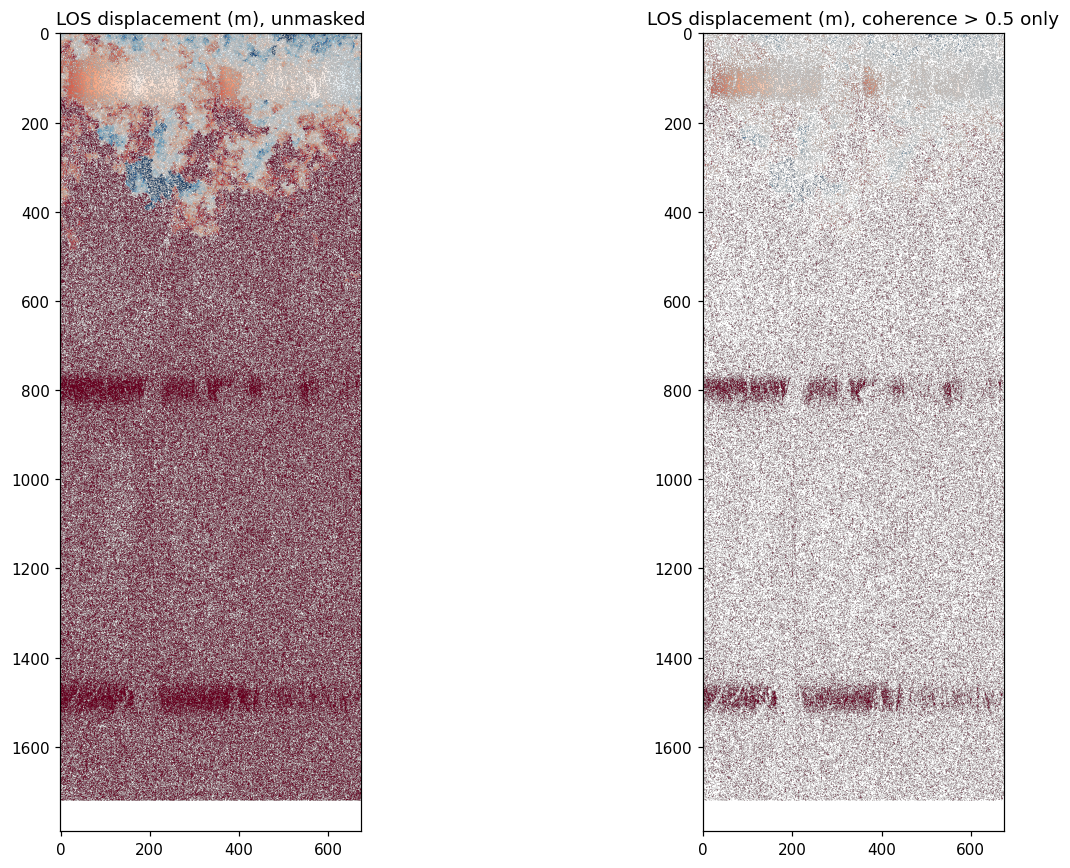

In [7]:
# Step 7: convert unwrapped phase to line-of-sight displacement, d = -(lambda / 4*pi) * delta_phi.

# 1. phase_to_los applies that conversion using the radar wavelength (~5.55 cm here, so one
#    full fringe/2*pi of phase corresponds to ~2.8 cm of LOS motion).
los = insar.phase_to_los(unwrapped, ann_ref["wavelength"])

# 2. Report the full (unmasked) field's range as a baseline -- see the markdown below for
#    why this range is implausibly large and not real ground motion.
print(f"LOS displacement, full unwrapped field: {np.nanmin(los):.3f} to {np.nanmax(los):.3f} m")


# 3. Apply a stricter coherence threshold (> 0.5) than the unwrapping mask used, and blank
#    out everything below it with NaN.
reliable = coh > 0.5
los_masked = np.where(reliable, los, np.nan)  # keep only reliable (coherent) pixels

# 4. Report the coherence-masked range and what fraction of the scene survives the mask.
print(f"LOS displacement, coherence > 0.5 only: {np.nanmin(los_masked):.3f} to {np.nanmax(los_masked):.3f} m "
      f"({100 * np.mean(reliable):.0f}% of the scene)")


# 5. Plot the unmasked vs. coherence-masked LOS displacement maps side by side for comparison.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(los, cmap="RdBu_r", vmin=-0.1, vmax=0.1)  # all pixels
axes[0].set_title("LOS displacement (m), unmasked")  # title
axes[1].imshow(los_masked, cmap="RdBu_r", vmin=-0.1, vmax=0.1)  # coherent pixels only
axes[1].set_title("LOS displacement (m), coherence > 0.5 only")  # title
plt.tight_layout()  # arrange

The unmasked field's full range (tens of centimetres in places) is not real ground motion --
it is a direct illustration of Step 9's warning and a common InSAR pitfall: at a mean coherence
of 0.35, SNAPHU cannot reliably resolve 2*pi ambiguities over large parts of this scene, and
wrong integer-cycle jumps (not noise, discrete 2.8 cm-multiple errors) are exactly what produce
implausibly large unwrapped values.

Restricting to coherence > 0.5 does **not** fix this, and the way it fails is itself
instructive: the surviving pixels sit almost entirely inside the coherence bands from Step 3,
and within each band the displacement comes out as one consistent but implausibly large value
(tens of centimetres), not speckle noise. Each coherent band is an island surrounded by
decorrelated (masked) pixels, so SNAPHU has no reliable path connecting it back to the rest of
the scene's unwrapping network -- it can integrate the right *relative* phase inside the island
but still land on the wrong absolute 2*pi count for it as a whole. A per-pixel coherence
threshold cannot catch this, because every pixel inside the island genuinely is coherent; what
is missing is *connectivity* to a reliable reference. This is exactly the problem persistent-
scatterer and SBAS methods are built to avoid, by keeping a redundant network of connections
between reliable points rather than unwrapping one interferogram's full 2-D field
(``07_03_01_05_PSInSAR.ipynb``, ``07_03_01_06_InSAR_SBAS.ipynb``) -- not something a single
pair can fix.


### Geocode

`terrain_correct` places the multilooked LOS and coherence layers onto the DEM's own map grid,
range-Doppler style, using each row's zero-Doppler time and the orbit.


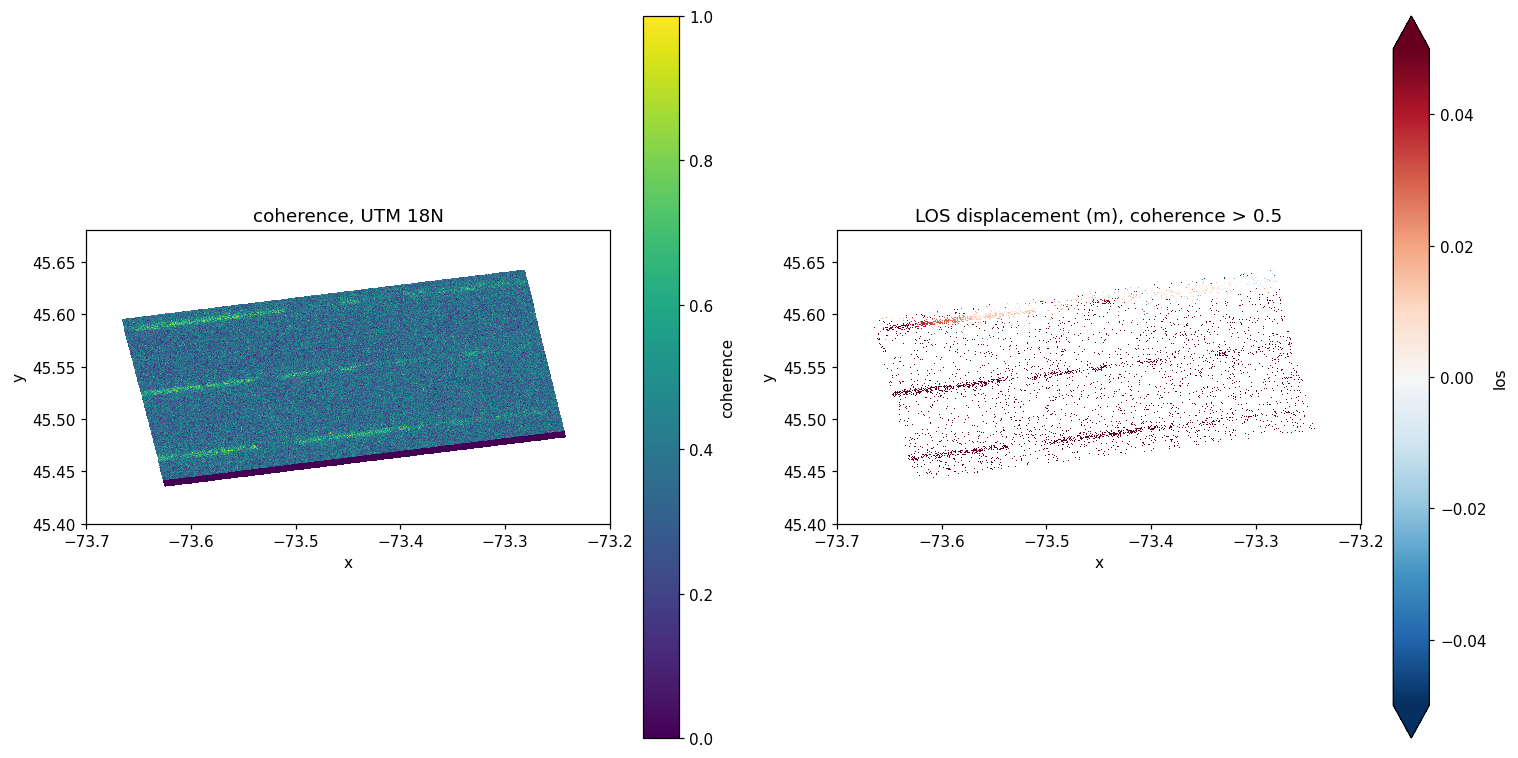

In [8]:
# Step 8: geocode the multilooked LOS and coherence layers onto the DEM's own map grid.

# 1. Reconstruct the per-row zero-Doppler azimuth time at full (pre-multilook) resolution,
#    from the reference annotation's single burst start time plus the azimuth time interval
#    (lines_per_burst rows, each one azimuth_time_interval apart).
lpb = ann_ref["lines_per_burst"]
az_time_full = (ann_ref["bursts"][0]["azimuth_time"]  # azimuth time of every line
               + (np.arange(lpb) * ann_ref["azimuth_time_interval"] * 1e9).astype("timedelta64[ns]"))

# 2. Subsample that per-row time to match the 4x azimuth multilooking used for every InSAR
#    product above, truncated to the actual (multilooked) image height.
az_time_ml = az_time_full[::LOOKS[0]][:los.shape[0]]

# 3. Near-range slant range (from the two-way slant-range time, converted with the speed of
#    light) and the multilooked range pixel spacing -- both needed by the range-Doppler
#    terrain correction to map each (line, sample) to a slant range and ground position.
near_range = ann_ref["slant_range_time"] * s1.SPEED_OF_LIGHT / 2
range_spacing_ml = ann_ref["range_pixel_spacing"] * LOOKS[1]  # range pixel size after multilooking


# 4. terrain_correct: range-Doppler project the multilooked LOS displacement and coherence
#    layers from radar (line/sample) geometry onto the DEM's map grid, using each row's
#    zero-Doppler time together with the reference orbit to locate it on the ground.
geo = s1.terrain_correct({"los": los, "coherence": coh}, az_time_ml, near_range, range_spacing_ml,
                         ann_ref["orbit"], dem)

# 5. Apply the same coherence > 0.5 reliability mask used in Step 7, now to the geocoded LOS.
geo_los = geo["los"].where(geo["coherence"] > 0.5)


# 6. Plot the geocoded coherence and masked LOS displacement maps side by side in map
#    projection (UTM 18N) for direct visual comparison against the radar-geometry versions.
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
geo["coherence"].plot(ax=axes[0], cmap="viridis", vmin=0, vmax=1)  # geocoded coherence
axes[0].set_title("coherence, UTM 18N")  # title
geo_los.plot(ax=axes[1], cmap="RdBu_r", vmin=-0.05, vmax=0.05)  # geocoded LOS displacement
axes[1].set_title("LOS displacement (m), coherence > 0.5")  # title
for ax in axes:  # for both panels
    ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange

The geocoded coherence map confirms the banding runs close to constant latitude rather than
parallel to the satellite's tilted ground track -- the detail that ruled out a radar-geometry
processing artifact and pointed toward a real, land-management-linked explanation instead. The
geocoded LOS panel shows the unwrapping-island problem from Step 7 in map form: the surviving
points cluster almost entirely inside those same bands, each one a uniform, saturated colour --
an isolated coherent patch that kept its internal phase relationships but landed on the wrong
absolute 2*pi count, not a real, spatially consistent displacement field.

## Takeaways and limitations

- Every InSAR workflow step in the intro notebook now has a real implementation exercised on a
  real RCM pair: `radarsat.read_rcm_annotation` (Step 1's product reading, new in this
  notebook) feeds `sentinel1.back_geocode`/`resample_slc` (Step 2) unchanged, and
  `geolattice.rsense.insar`'s `differential_interferogram`/`multilook_complex` (Step 3-4),
  `goldstein_filter` (Step 5), `unwrap` (Step 6), `phase_to_los` (Step 7) and
  `sentinel1.terrain_correct` (Step 8) needed no RCM-specific changes at all -- they were
  already sensor-agnostic.
- Fixed a real latent bug this pair exposed: `terrain_correct` assumed row azimuth-time always
  increases with row number (true for every Sentinel-1 product used so far); this RCM product
  stores rows in decreasing-time order, which silently broke the time-to-row lookup
  (`np.interp` needs ascending `xp`). Fixed by sorting ascending internally when needed --
  harmless for the existing ascending case, correct for this one.
- **Scope of `read_rcm_annotation`**: Stripmap beams only (continuous single-beam imaging, as
  used here). A ScanSAR beam (e.g. the `SC30MCP*` compact-pol beams the same EODMS search
  turned up densely over Montreal) packs several sub-beams with their own burst-like timing,
  which this reader does not parse -- a natural next step given how much ScanSAR SLC coverage
  is actually available.
- No time series here (one pair only) -- `geolattice.rsense.insar.sbas`'s network tools from the
  Sentinel-1 SBAS tutorial apply equally once more RCM dates are coregistered the same way.
- The coherence-banding interpretation (Quebec strip-field land management) is a plausible
  reading of the evidence gathered, not a verified one.

#### References

- Natural Resources Canada / EODMS, RCM Image Products STAC collection
  (`https://www.eodms-sgdot.nrcan-rncan.gc.ca/search/`) and Data Delivery Service API.
- Small, D. (2011). *Flattening gamma: Radiometric terrain correction for SAR imagery.*
  IEEE TGRS, 49(8), 3081-3093.
- Goldstein, R. M., & Werner, C. L. (1998). *Radar interferogram filtering for geophysical
  applications.* Geophysical Research Letters, 25(21), 4035-4038.
- Chen, C. W., & Zebker, H. A. (2002). *Two-dimensional phase unwrapping with use of statistical
  models for cost functions in nonlinear optimization* (SNAPHU). JOSA A, 19(5), 1026-1037.
